# Figure 1

![Full Figure](../figures/fig01_FULL.png)


- Panel A: task-event timing and violation window.
- Panel B: three consecutive example sessions (animal/session from selected rows).
- Panels C–F: trained-dataset summaries (session histograms and choice distribution).

**Outputs:** `figures/fig01b_example_sequences.png`, `figures/fig01c_trials_per_session.png`, `figures/fig01d_hit_rate.png`, `figures/fig01e_choice_percentages.png`, and `figures/fig01f_violation_rate.png`.


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from matplotlib.colors import to_rgb

from violations_glm.config import (
    CHOICE_ORDER,
    CHOICE_PALETTE,
    HIT_COLOR,
    LEFT_COLOR,
    N_TRIAL_COLOR,
    RIGHT_COLOR,
    VIOLATION_COLOR,
)
from violations_glm.io import load_trials_df
from violations_glm.plotting import configure_publication_dpi, save_figure
from violations_glm.transforms import (
    select_example_sessions,
    session_choice_percentages,
    session_performance_summary,
)

configure_publication_dpi()

sns.set_context(
    "notebook",
    rc={
        "font.size": 20,
        "axes.titlesize": 20,
        "axes.labelsize": 20,
        "axes.titleweight": "bold",
        "xtick.labelsize": 15,
        "ytick.labelsize": 15,
    },
)

In [2]:
trials = load_trials_df()
session_summary = session_performance_summary(trials)
session_summary["hit_rate_percentage"] = session_summary["hit_rate"] * 100
session_summary["viol_rate_percentage"] = session_summary["viol_rate"] * 100
choice_dist = session_choice_percentages(trials)

## Panel B — Representative behavioral sequences

Three consecutive trained sessions are shown (animal and session IDs come from the selected example rows). Rows are ordered L / V / R (top to bottom). Color encodes choice side (incorrects slightly darker); filled circles are correct, × marks are incorrect, and open downward triangles are violations.


In [3]:
examples = select_example_sessions(
    trials, animal_id="W074", sessions=(201, 297, 376))
sessions = examples["session"].unique()

/var/folders/g4/l0_yc2ss2nvdqk_13sp3z6fc0000gn/T/ipykernel_50651/2235052181.py:31: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax.scatter(
/var/folders/g4/l0_yc2ss2nvdqk_13sp3z6fc0000gn/T/ipykernel_50651/2235052181.py:31: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax.scatter(
/var/folders/g4/l0_yc2ss2nvdqk_13sp3z6fc0000gn/T/ipykernel_50651/2235052181.py:31: UserWarning: *c* argument looks like a single numeric RGB or RG

PosixPath('/Users/jessbreda/Documents/github/Breda-Violations-GLM-PLOSOne/figures/fig01b_example_sequences.png')

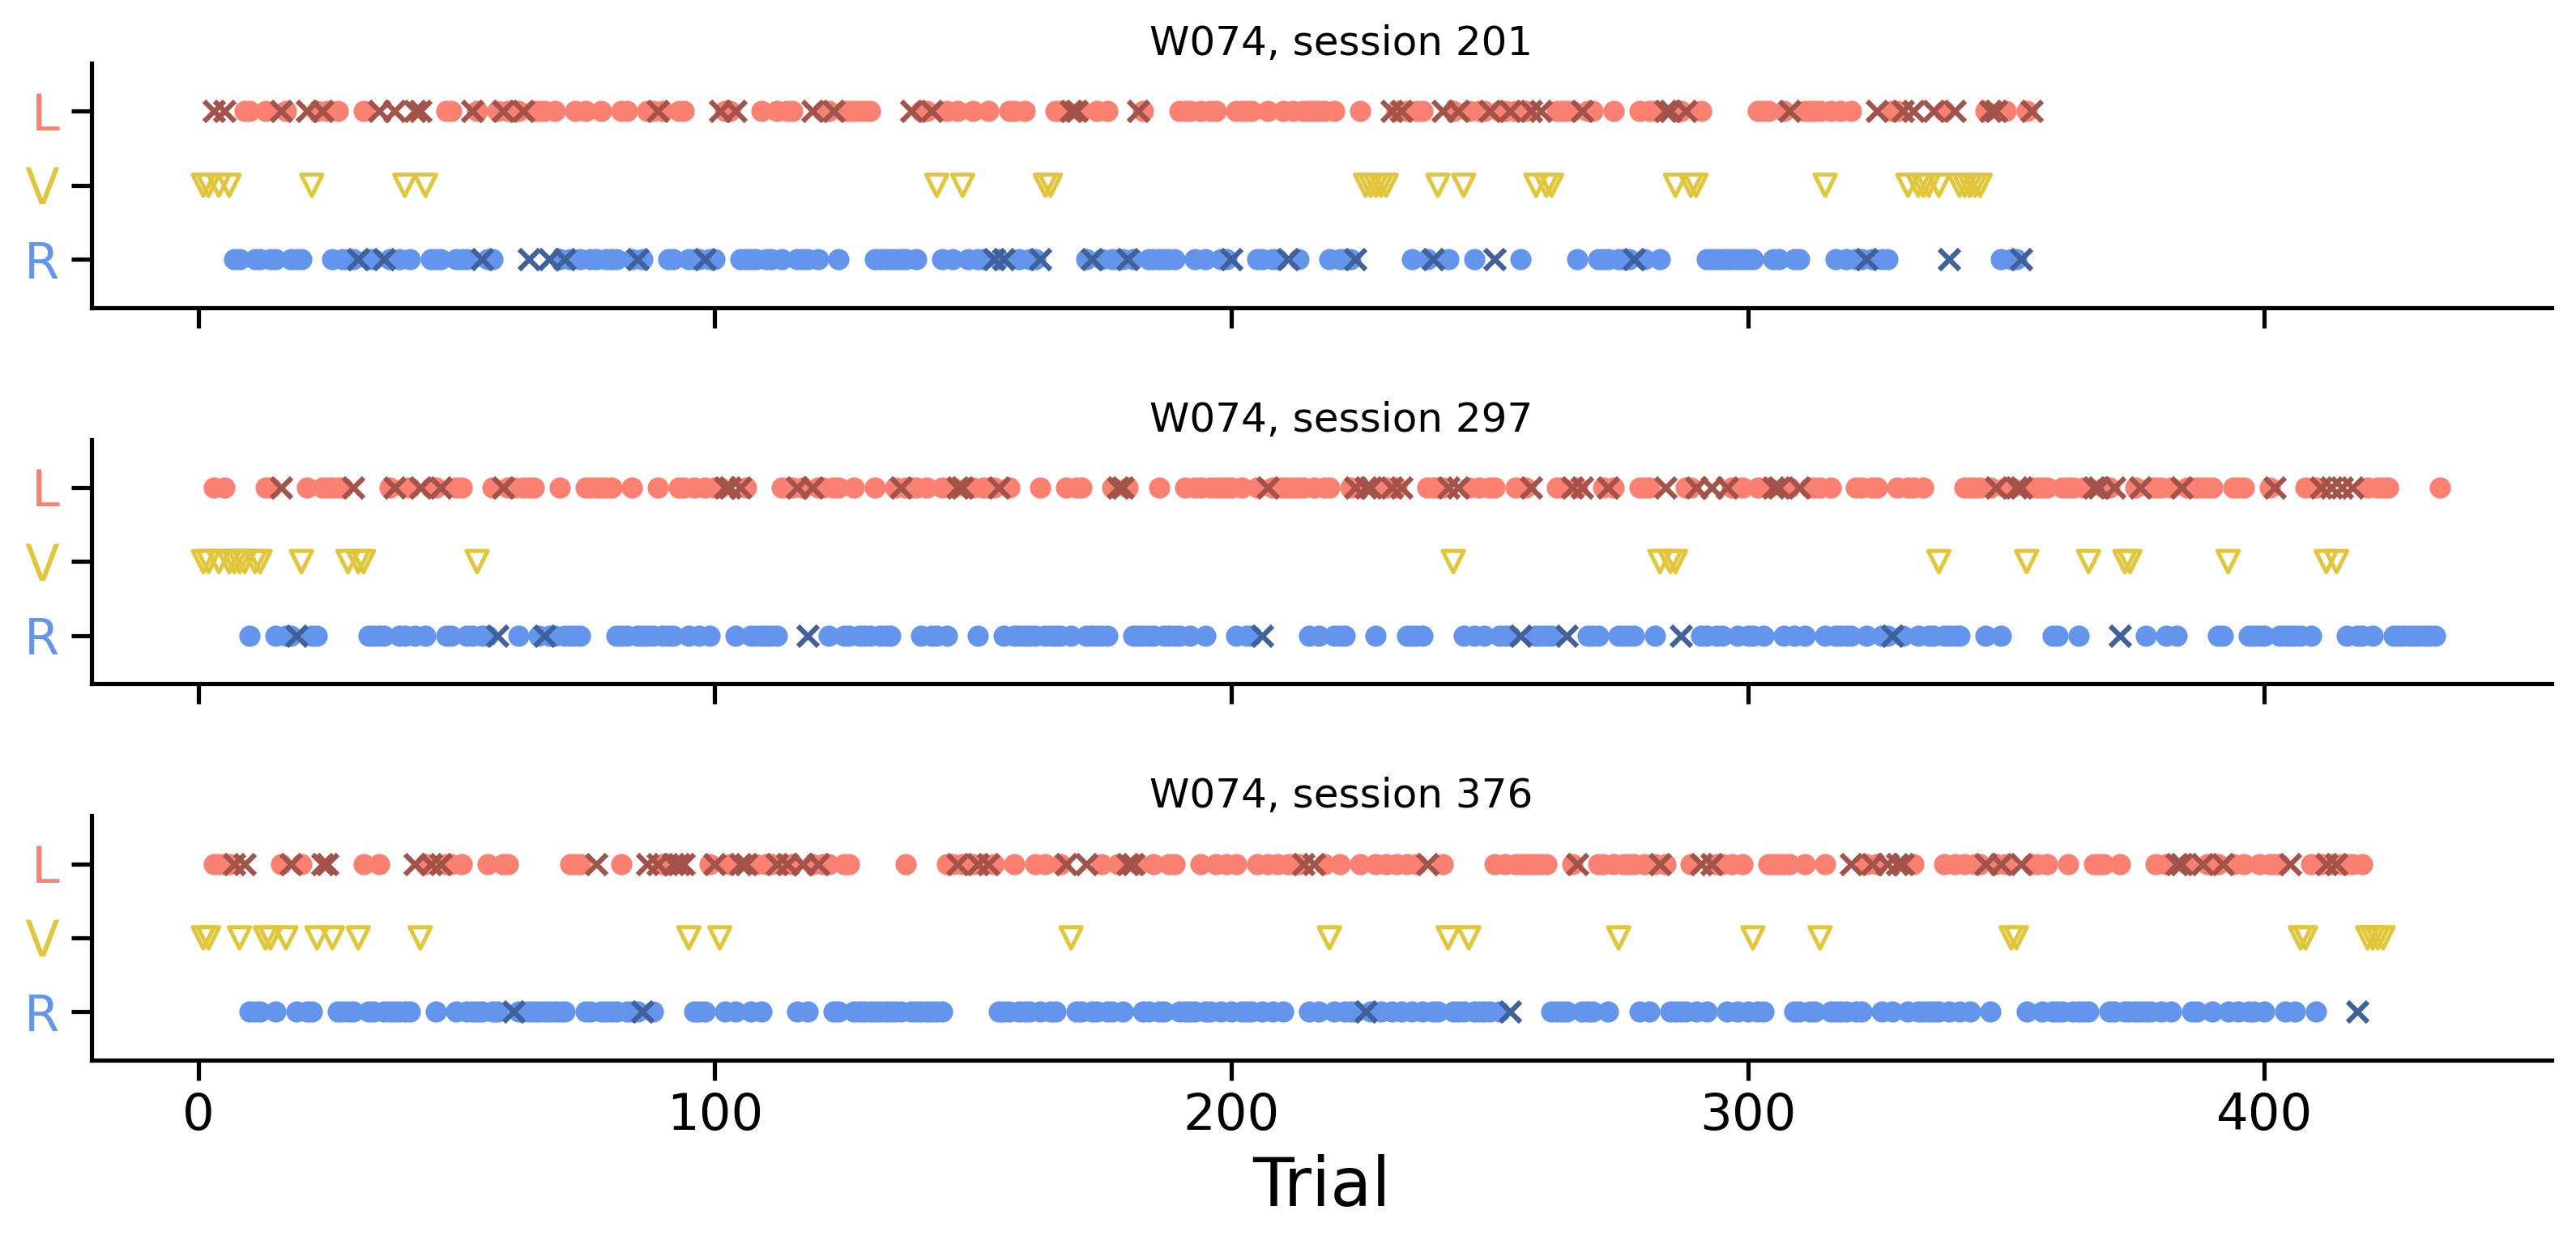

In [ ]:
# Choice → y: Right bottom, Violation middle, Left top
choice_styles = (
    (0, 2, LEFT_COLOR, "Left"),
    (1, 0, RIGHT_COLOR, "Right"),
)

fig, axes = plt.subplots(
    len(sessions), 1, figsize=(11, 6), sharex=True, sharey=True
)
for ax_i, (ax, session) in enumerate(zip(axes, sessions, strict=True)):
    session_df = examples.loc[examples["session"] == session]
    animal_id = session_df["animal_id"].iloc[0]
    for choice, y, color, label in choice_styles:
        correct = session_df.loc[
            (session_df["choice"] == choice) & (session_df["hit"] == 1)
        ]
        incorrect = session_df.loc[
            (session_df["choice"] == choice) & (session_df["hit"] == 0)
        ]
        incorrect_color = tuple(c * 0.65 for c in to_rgb(color))
        ax.scatter(
            correct["trial"],
            np.full(len(correct), y),
            s=28,
            marker="o",
            c=color,
            label=label if ax_i == 0 else None,
        )
        ax.scatter(
            incorrect["trial"],
            np.full(len(incorrect), y),
            s=36,
            marker="x",
            c=incorrect_color,
        )
    violations = session_df.loc[session_df["choice"] == 2]
    ax.scatter(
        violations["trial"],
        np.full(len(violations), 1),
        s=40,
        marker="v",
        facecolors="none",
        edgecolors=VIOLATION_COLOR,
        linewidths=1.2,
        label="Violation" if ax_i == 0 else None,
    )
    ax.set(
        yticks=[0, 1, 2],
        yticklabels=["R", "V", "L"],
        ylim=(-0.65, 2.65),
    )
    ax.text(
        0.43,
        1,
        f"{animal_id}, session {session}",
        transform=ax.transAxes,
        ha="left",
        va="bottom",
        fontsize=12,
        # fontweight="bold",
    )
    for tick, color in zip(
        ax.get_yticklabels(), (RIGHT_COLOR, VIOLATION_COLOR, LEFT_COLOR)
    ):
        tick.set_color(color)
    ax.spines[["top", "right"]].set_visible(False)

axes[-1].set_xlabel("Trial")
handles, labels = axes[0].get_legend_handles_labels()
# fig.legend(handles, labels, frameon=False, ncol=3, loc="upper center")
fig.tight_layout(rect=(0, 0, 1, 0.92))
save_figure(fig, "fig01b_example_sequences")

## Panel C — Trials per session

Session-level trial counts are pooled across animals. The dashed line marks the median.


,index,n_trials
0,count,5210.000000
1,mean,358.157965
2,std,140.468588
3,min,50.000000
4,25%,264.000000
5,50%,348.000000
6,75%,432.000000
7,max,1494.000000


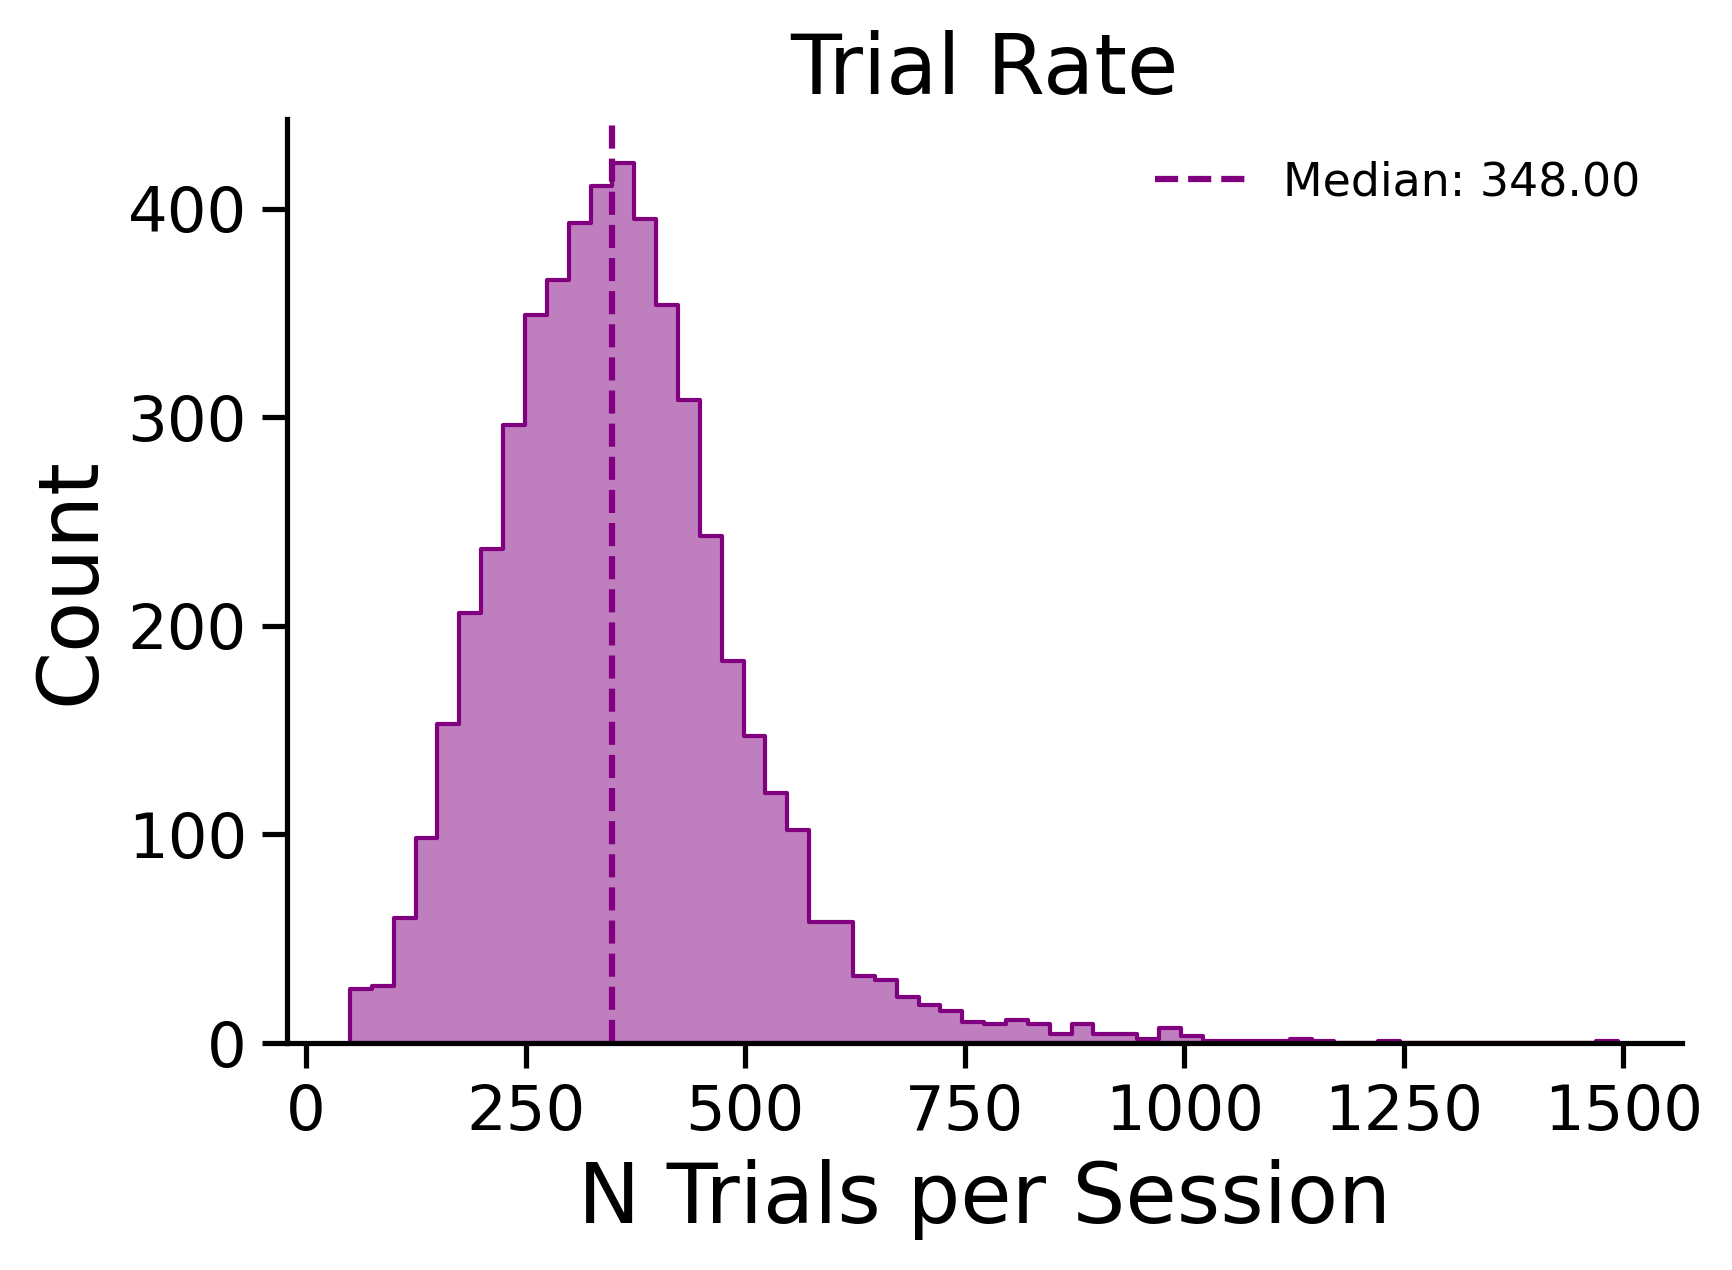

In [5]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.despine(ax=ax)
sns.histplot(
    data=session_summary,
    x="n_trials",
    ax=ax,
    color=N_TRIAL_COLOR,
    element="step",
    alpha=0.5,
    binwidth=25,
)
median_value = session_summary["n_trials"].median()
ax.axvline(
    median_value,
    color=N_TRIAL_COLOR,
    linestyle="--",
    label=f"Median: {median_value:.2f}",
)
ax.set(xlabel="N Trials per Session", title="Trial Rate")
ax.legend(loc="upper right", frameon=False)
save_figure(fig, "fig01c_trials_per_session")


session_summary["n_trials"].describe().reset_index()

## Panel D — Hit rate

Session hit rates are shown as percentages. The dashed line marks the median.


,index,hit_rate_percentage
0,count,5210.000000
1,mean,81.879281
2,std,6.195436
3,min,27.272727
4,25%,77.702703
5,50%,81.502115
6,75%,86.069093
7,max,97.877358


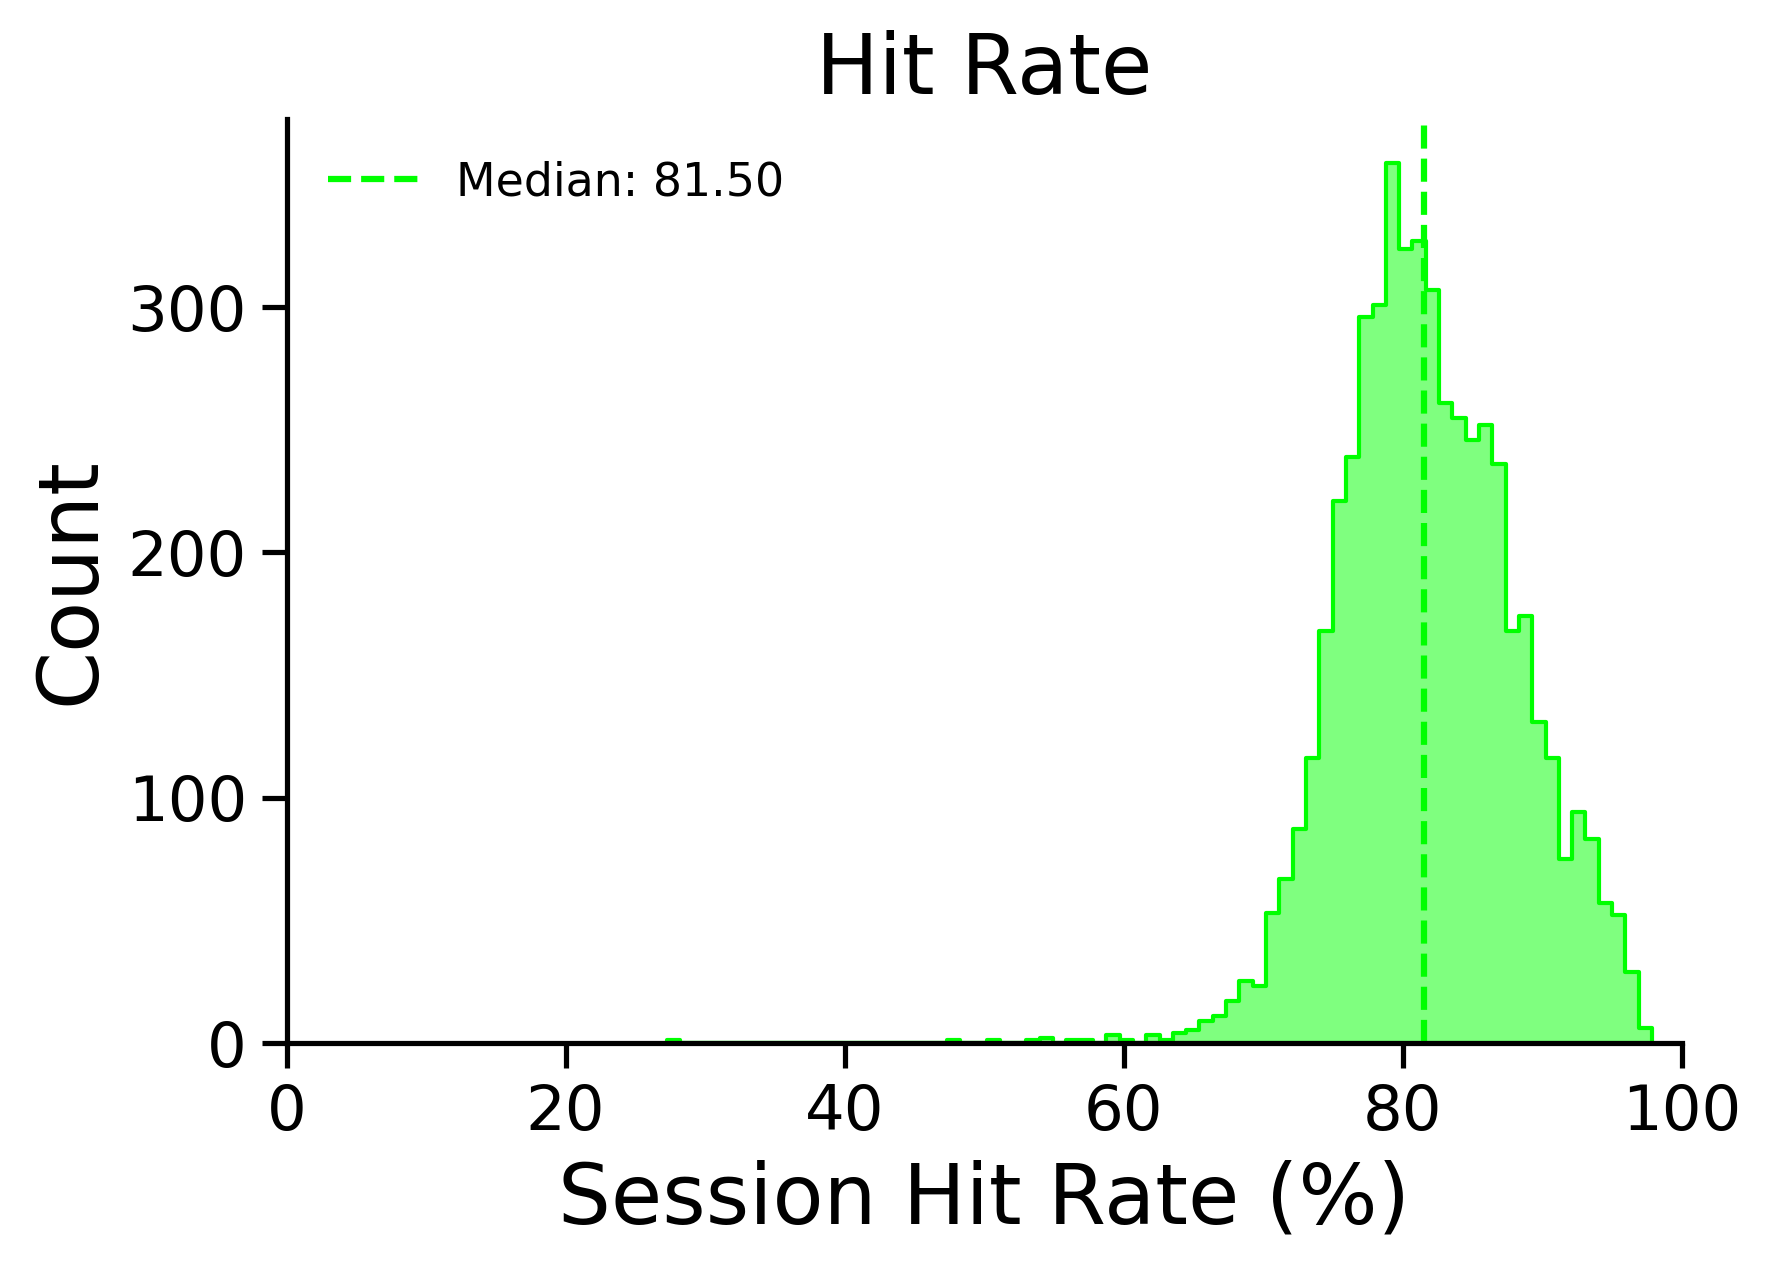

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.despine(ax=ax)
sns.histplot(
    data=session_summary,
    x="hit_rate_percentage",
    ax=ax,
    color=HIT_COLOR,
    element="step",
    alpha=0.5,
)
median_value = session_summary["hit_rate_percentage"].median()
ax.axvline(
    median_value,
    color=HIT_COLOR,
    linestyle="--",
    label=f"Median: {median_value:.2f}",
)
ax.set(xlabel="Session Hit Rate (%)", xlim=(0, 100), title="Hit Rate")
ax.legend(loc="upper left", frameon=False)
save_figure(fig, "fig01d_hit_rate")


session_summary["hit_rate_percentage"].describe().reset_index()

## Panel E — Choice distributions

Each point is one session. Bars show the mean session percentage ± SE across the pooled session rows.


PosixPath('/Users/jessbreda/Documents/github/Breda-Violations-GLM-PLOSOne/figures/fig01e_choice_percentages.png')

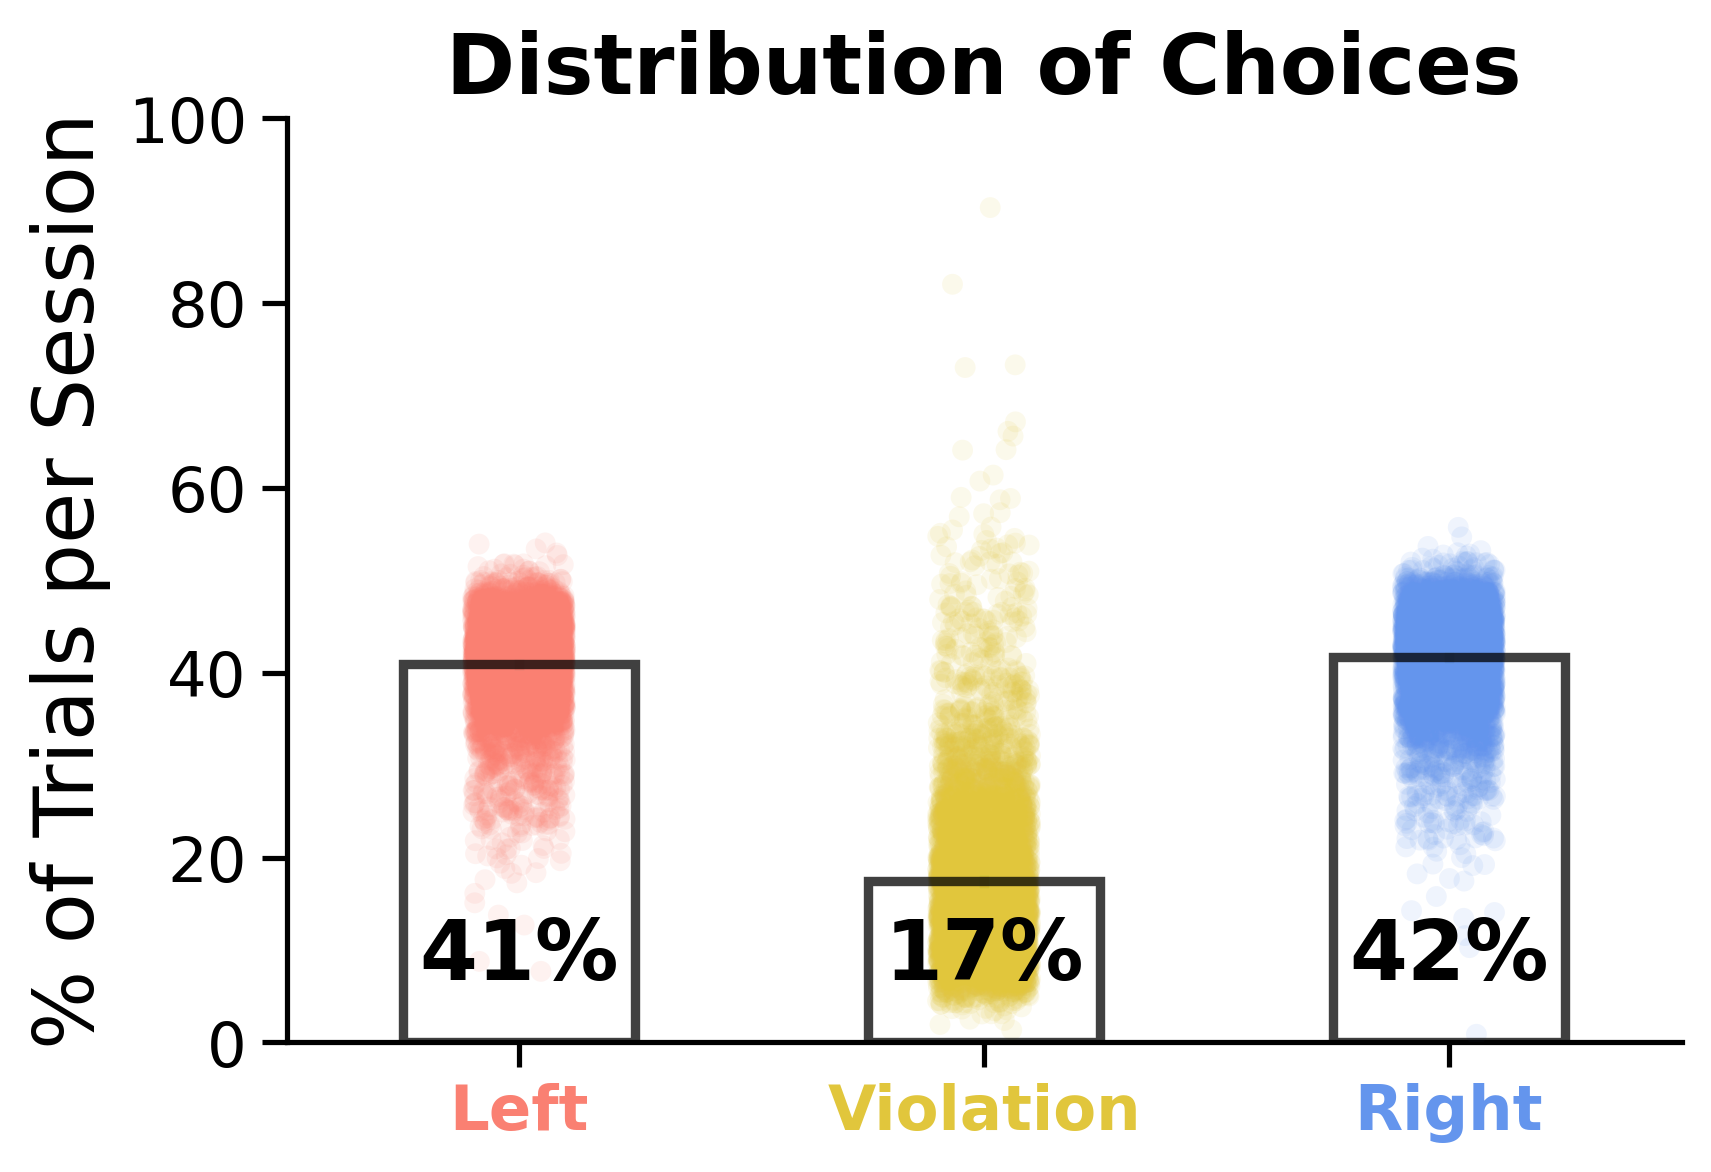

In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.despine(ax=ax)
sns.barplot(
    x="Choice",
    y="percentage",
    data=choice_dist,
    ax=ax,
    width=0.5,
    fill=False,
    zorder=10,
    errorbar="se",
    color="k",
    alpha=0.75,
    order=list(CHOICE_ORDER),
    hue_order=list(CHOICE_ORDER),
)
sns.stripplot(
    x="Choice",
    y="percentage",
    data=choice_dist,
    ax=ax,
    alpha=0.10,
    palette=list(CHOICE_PALETTE),
    hue="Choice",
    order=list(CHOICE_ORDER),
    hue_order=list(CHOICE_ORDER),
    legend=False,
)
ax.set(xlabel="", ylabel=r"% of Trials per Session", ylim=(0, 100))
ax.set_title("Distribution of Choices", fontweight="bold")
for choice in CHOICE_ORDER:
    percentage = choice_dist.loc[choice_dist["Choice"]
                                 == choice, "percentage"].mean()
    ax.text(
        x=choice,
        y=5,
        s=f"{percentage:.0f}%",
        ha="center",
        va="bottom",
        fontweight="bold",
    )
tick_colors = {
    "Left": LEFT_COLOR,
    "Violation": VIOLATION_COLOR,
    "Right": RIGHT_COLOR,
}
for label in ax.get_xticklabels():
    label.set_color(tick_colors[label.get_text()])
    label.set_fontweight("bold")
save_figure(fig, "fig01e_choice_percentages")

## Panel F — Violation rate

Session violation rates are shown as percentages. The dashed line marks the median.


,index,viol_rate_percentage
0,count,5210.000000
1,mean,17.421760
2,std,9.166983
3,min,1.345291
4,25%,11.051568
5,50%,15.240999
6,75%,21.401535
7,max,90.350877


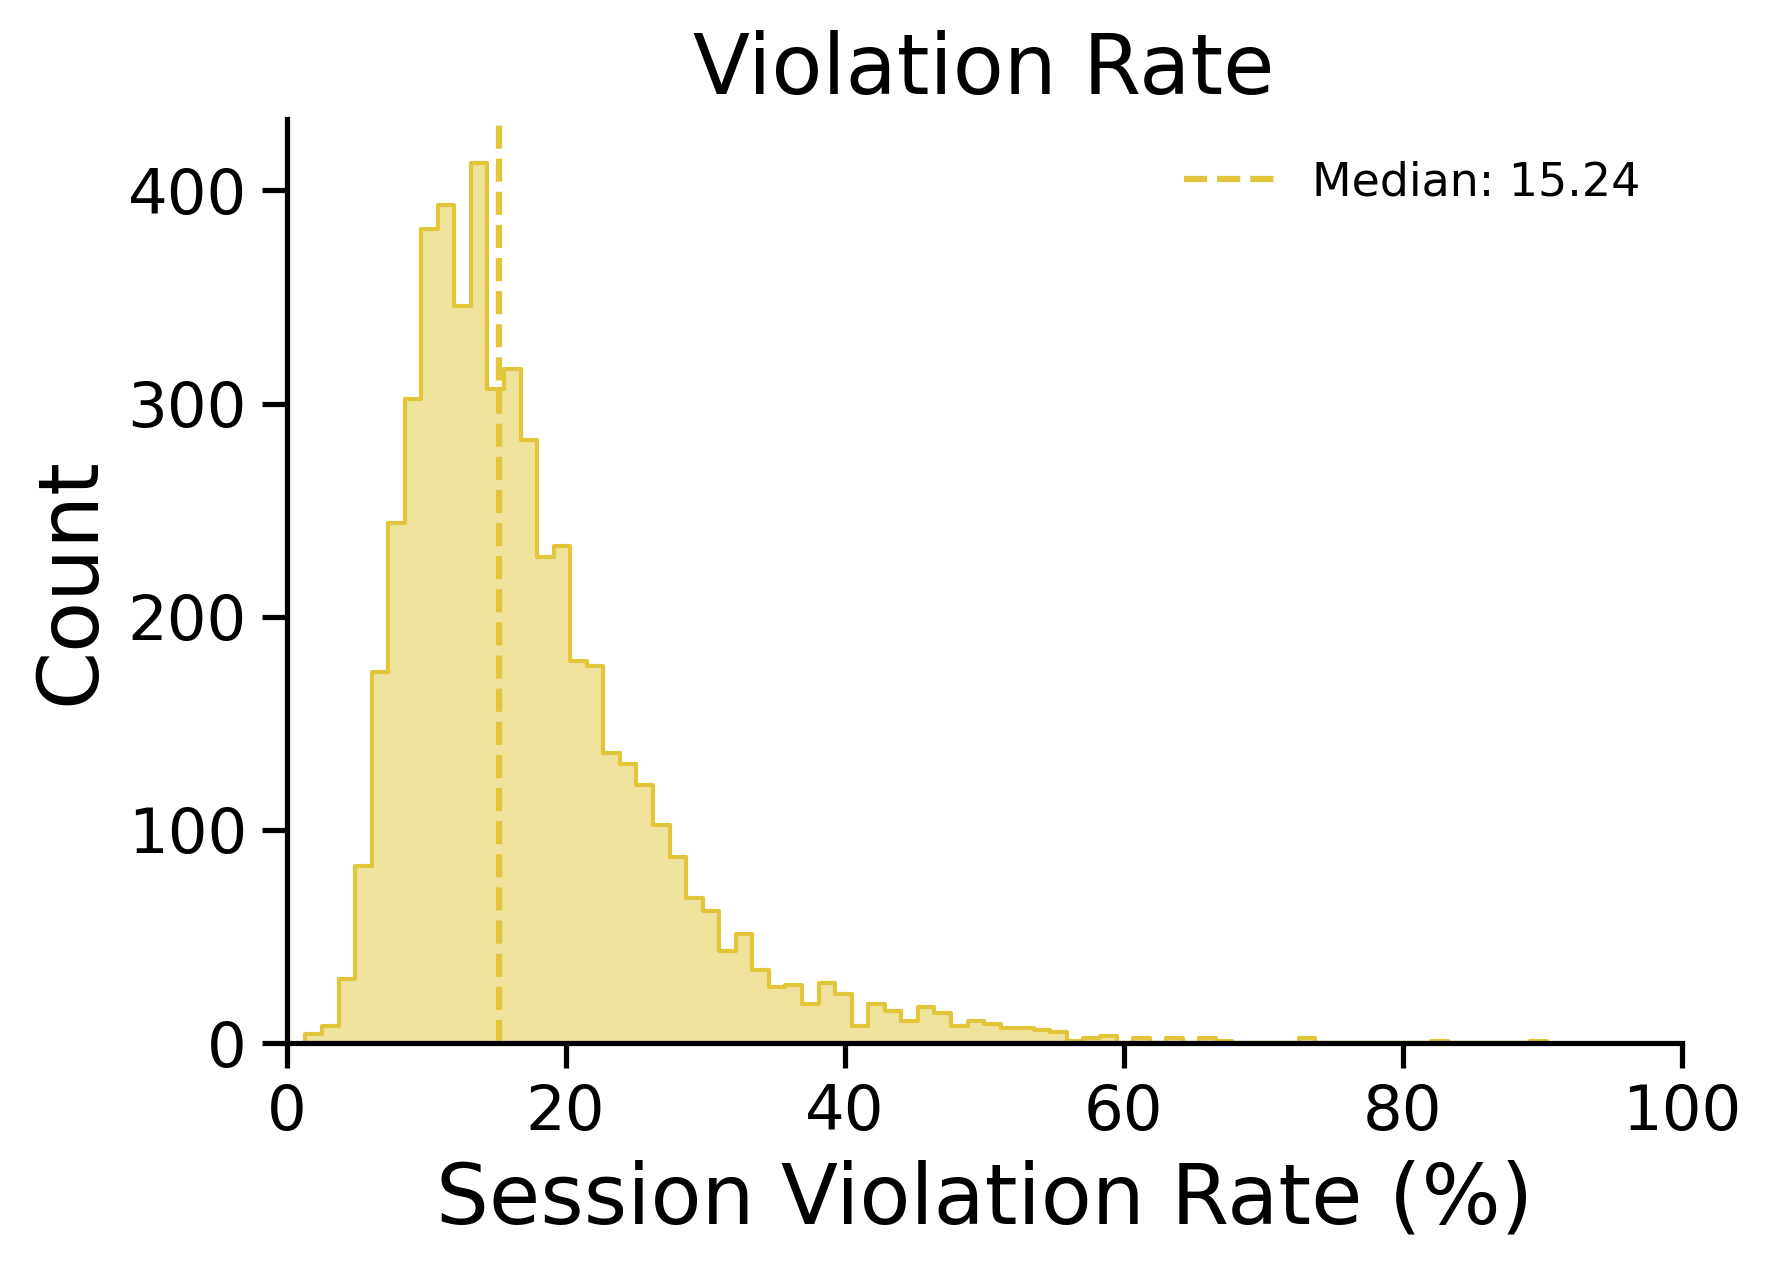

In [8]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.despine(ax=ax)
sns.histplot(
    data=session_summary,
    x="viol_rate_percentage",
    ax=ax,
    color=VIOLATION_COLOR,
    element="step",
    alpha=0.5,
)
median_value = session_summary["viol_rate_percentage"].median()
ax.axvline(
    median_value,
    color=VIOLATION_COLOR,
    linestyle="--",
    label=f"Median: {median_value:.2f}",
)
ax.set(
    xlabel="Session Violation Rate (%)",
    xlim=(0, 100),
    title="Violation Rate",
)
ax.legend(loc="upper right", frameon=False)
save_figure(fig, "fig01f_violation_rate")


session_summary["viol_rate_percentage"].describe().reset_index()